epoch: 1; G_loss: 0.649551; D_loss: 1.646515


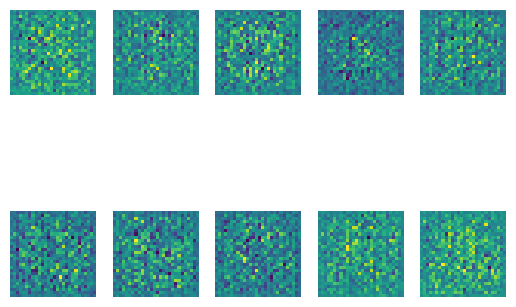

epoch: 100; G_loss: 0.902746; D_loss: 1.038867


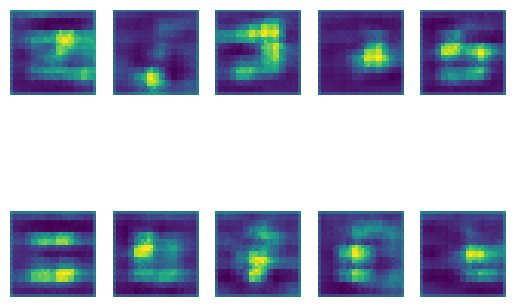

In [2]:
#!pip install -q tensorflow-gpu==2.0.0-rc1
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

batch_size = 200
epochs = 100
z_dim = 100

# Noise for visualization
z_vis = tf.random.normal([10, z_dim])
y_vis = tf.constant(np.eye(10), dtype='float32')

# Load data
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train / 255.0
y_train = tf.one_hot(y_train, depth=10, dtype='float32')
data_iter = iter(tf.data.Dataset.from_tensor_slices((x_train, y_train)).shuffle(4 * batch_size).batch(batch_size).repeat())


# Models
def Generator():
  z = tf.keras.layers.Input(shape=(z_dim,), dtype='float32')
  y = tf.keras.layers.Input(shape=(10,), dtype='float32')
  tr = tf.keras.layers.Input(shape=(1,), dtype='bool')

  x = tf.keras.layers.concatenate([z, y])
  x = tf.keras.layers.Dense(3 * 3 * 512)(x)
  x = tf.keras.layers.Reshape((3, 3, 512))(x)
  
  x = tf.keras.layers.Conv2DTranspose(256, 3, 2, 'valid')(x)
  x = tf.nn.leaky_relu(tf.keras.layers.BatchNormalization()(x, training=tr))
  
  x = tf.keras.layers.Conv2DTranspose(128, 4, 2, 'same')(x)
  x = tf.nn.leaky_relu(tf.keras.layers.BatchNormalization()(x, training=tr))
  
  x = tf.keras.layers.Conv2DTranspose(1,  4, 2, 'same', activation='sigmoid')(x)
  out = tf.keras.layers.Reshape((28, 28))(x)
  
  return tf.keras.Model(inputs=[z, y, tr], outputs=out)


def Discriminator():
  X = tf.keras.layers.Input(shape=(28, 28), dtype='float32')
  Y = tf.keras.layers.Input(shape=(10,), dtype='float32')
  tr = tf.keras.layers.Input(shape=(1,), dtype='bool')
  
  y = tf.tile(tf.reshape(Y,[-1, 1, 1, 10]), [1, 28, 28, 1])
  x = tf.keras.layers.Reshape((28, 28, 1))(X)
  x = tf.keras.layers.concatenate([x, y])
  
  x = tf.keras.layers.Conv2D(128,  4, 2, 'same')(x)
  
  x = tf.keras.layers.Conv2D(256,  4, 2, 'same')(x)
  x = tf.nn.leaky_relu(tf.keras.layers.BatchNormalization()(x, training=tr))
  
  x = tf.keras.layers.Conv2D(512, 4, 2, 'same')(x)
  x = tf.nn.leaky_relu(tf.keras.layers.BatchNormalization()(x, training=tr))
  
  out = tf.keras.layers.Dense(1)(x)
  
  return tf.keras.Model(inputs=[X, Y, tr], outputs=out)


G = Generator()
D = Discriminator()

# Loss functions
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits = True)
def G_loss(D, x_fake, y):
  return cross_entropy(tf.ones_like(D([x_fake, y, True])), D([x_fake, y, True]))
def D_loss(D, x_real, x_fake, y):
  return cross_entropy(tf.ones_like(D([x_real, y, True])), D([x_real, y, True])) \
      + cross_entropy(tf.zeros_like(D([x_fake, y, True])), D([x_fake, y, True]))

# Optimizers
G_opt = tf.keras.optimizers.Adam(2e-4)
D_opt = tf.keras.optimizers.Adam(2e-4)

# Train
for epoch in range(epochs):
  z_mb = tf.random.normal([batch_size, z_dim])
  x_real, y = next(data_iter)
  # Record operations
  with tf.GradientTape() as G_tape, tf.GradientTape() as D_tape:  
    x_fake = G([z_mb, y, True])
    G_loss_curr = G_loss(D, x_fake, y)
    D_loss_curr = D_loss(D, x_real, x_fake, y)
  # Gradients
  G_grad = G_tape.gradient(G_loss_curr, G.trainable_variables)
  D_grad = D_tape.gradient(D_loss_curr, D.trainable_variables)
  # Apply gradients
  G_opt.apply_gradients(zip(G_grad, G.trainable_variables))
  D_opt.apply_gradients(zip(D_grad, D.trainable_variables))
  
  if epoch % 99 == 0:
    # Print results
    print('epoch: {}; G_loss: {:.6f}; D_loss: {:.6f}'.format(epoch+1, G_loss_curr, D_loss_curr))
    # Plot generated images
    for i in range(10):
      plt.subplot(2, 5, i+1)
      plt.imshow(G([z_vis, y_vis, False])[i,:,:] * 255.0)
      plt.axis('off')
    plt.show()